# 02 — Causal Lift Estimation (Intention-to-Treat Effect)

**Goal:** does advertising actually generate additional conversions, and how much?

Because treatment assignment is randomized (validated in notebook 01), the difference in conversion rates between the treatment and control groups is an **unbiased estimate of the causal effect** of ad eligibility — the intention-to-treat (ITT) effect. This is the primary estimate for this project: no regression adjustment or matching is needed to make it valid.

In [1]:
import sys
sys.path.append('..')
from src.data_loader import load_sample
from src.causal_estimates import compute_itt_lift

df = load_sample()
result = compute_itt_lift(df)
print(result.summary())

Treatment conversion rate: 0.3196% (n=1,188,739)
Control conversion rate:   0.1964% (n=209,220)
Absolute lift: 0.1231%  (95% CI: [0.1016%, 0.1447%])
Relative lift: 62.68%
Incremental conversions (in treatment group): 1,464
z = 9.48, p = 0.00e+00 (significant at alpha=0.05)
Logistic regression cross-check: treatment coef p-value = 6.25e-21


## Visualizing the lift

The chart below shows the raw conversion rates in each group, with the treatment bar's 95% confidence interval for the *difference* annotated — this is the number that matters, not just each bar in isolation.

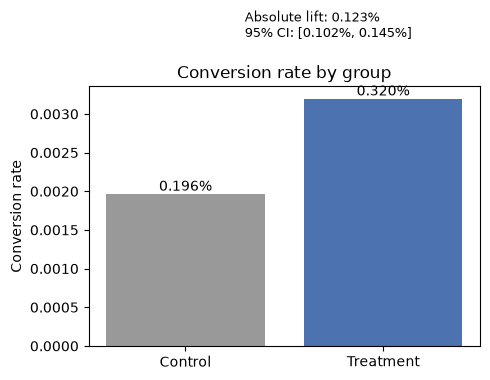

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(
    ['Control', 'Treatment'],
    [result.conv_rate_control, result.conv_rate_treatment],
    color=['#999999', '#4C72B0'],
)
ax.set_ylabel('Conversion rate')
ax.set_title('Conversion rate by group')
for bar, val in zip(bars, [result.conv_rate_control, result.conv_rate_treatment]):
    ax.text(bar.get_x() + bar.get_width() / 2, val, f'{val:.3%}', ha='center', va='bottom')
ax.annotate(
    f'Absolute lift: {result.absolute_lift:.3%}\n95% CI: [{result.ci_low:.3%}, {result.ci_high:.3%}]',
    xy=(1, result.conv_rate_treatment), xytext=(0.3, result.conv_rate_treatment * 1.25),
    fontsize=9,
)
plt.tight_layout()
plt.show()

## Interpreting the result

- **Absolute lift** is the number of percentage points of conversion rate caused by ad exposure — the quantity a budget decision should be based on.
- **Relative lift** is useful for communicating magnitude, but incremental-*conversions* and incremental-*revenue* (see notebook 03) are what actually matter for a spend decision.
- The **95% CI** excludes zero and the **p-value is far below 0.05**, so we can reject the hypothesis that advertising has no effect here — but note how *small* the absolute lift is relative to the raw treatment-group conversion rate. That gap is exactly what notebook 03 quantifies.